# `new_fixed_planner`, shifted by a markup

Takes `new_fixed_planner.ipynb` and puts a gross markup on prices, $p_i=\mu W/(\delta_i z_i)$.
Sections 1 and 2 are that notebook's model, copied verbatim.  **$\chi$ is left at 1 throughout**
and nothing else is touched.

The result is that a markup does nothing — not to the allocation, and not to optimal policy:

* $\log P$ shifts by exactly $\log\mu$ and every other object is bit-identical (section 3);
* the planner's optimal rate is unchanged to every digit, at $\mu=1$, $1.25$ and $2$ (section 4).

The reason is that $\mu$ is common to every firm, so it cancels from $p_i/P$ — and it cancels
*precisely because* the rate reprices every firm and every firm anticipates it.  A wedge that
hits all producers proportionally gives the interest rate nothing to work with.  This is the
same conclusion `fixed_wage_cohorts.ipynb` reaches from the other side: under a **flexible
wage** the nominal rate is neutral to $4\times10^{-16}$ at every $\mu\in[0.5,\,2]$.

## 1. Setup, copied from `new_fixed_planner.ipynb`

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

In [12]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE = 0.01
sigma = 5
gamma = 2.0               # 1.0 is new_fixed's calibration (log utility); 2.0 matches
                          # planner_consumption_deviation.  See section 8 -- gamma = 1
                          # is a knife edge at which the TFP experiment is degenerate.
eta = 2.0
chi = 1.0                        # C_ss = N_ss = A_ss = 1
PHI_YA = (1 + eta) / (gamma + eta)

beta = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1 = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1

A_SHOCK = 0.97                   # 3 per cent TFP decline
D_SHOCK = 0.01                   # 1 per cent demand shock
T = 30

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA}, chi={chi}, rho={rho:.6f}')
print(f'A shock = {A_SHOCK} ({100*(1-A_SHOCK):.0f}%),  demand shock = {100*D_SHOCK:.0f}%')
print(f'utility: {"log C" if abs(gamma-1) < 1e-12 else f"C^(1-{gamma})/(1-{gamma})"}'
      f'   -- note phi_ya = 1 exactly at gamma = 1; section 8 returns to this')

gamma=2.0, eta=2.0, phi_ya=0.75, chi=1.0, rho=0.010000
A shock = 0.97 (3%),  demand shock = 1%
utility: C^(1-2.0)/(1-2.0)   -- note phi_ya = 1 exactly at gamma = 1; section 8 returns to this


In [13]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS = len(tvals)
Z_PHYS = c * (tvals + N_array)          # physical output per firm, no discount factor

print(f'c = {c:.7f}   mean tau = {tau.mean():.4f}   firms = {NFIRMS}')
print(f'tau ranges over [{tvals.min()}, {tvals.max()}];  counts by tau = {np.bincount(tvals)}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_85106/1103498615.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   mean tau = 2.8885   firms = 269
tau ranges over [0, 13];  counts by tau = [ 1 31 97 66 48 18  1  2  0  2  1  1  0  1]


In [14]:
def generate_pattern_array_with_extra_rows(tau, shock=A_SHOCK):
    """Staggering matrix: which firms have re-optimised by period t."""
    tau = np.asarray(tau)
    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing = len(set(range(int(max(tau)) + 1)) - set(tau))
    A = np.ones((m + 2, n + missing), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms = tau[tau == i - 1]
        for j in range(len(firms)):
            A[i, n - i - j - count] = shock
        if len(firms) > 1:
            count += len(firms) - 1
    return np.vstack([A, np.ones(n + missing)])[:, 0:n - int(np.min(tau))]


A_PATTERN = generate_pattern_array_with_extra_rows(tau)
print('staggering matrix:', A_PATTERN.shape,
      f'-> TFP shock fully worked through by t = {A_PATTERN.shape[0] - 1}')

staggering matrix: (16, 269) -> TFP shock fully worked through by t = 15


## 2. The model, copied from `new_fixed_planner.ipynb`

In [15]:
TAUMAX_PAD = int(tvals.max()) + 2
T_PLUS_TAU = np.arange(T)[:, None] + tvals[None, :]   # delivery date of the batch started at t


def rate_matrix(r, T=T, truncated=False):
    """Row t = the rates a firm delivering at t discounts over, most recent lag first.

    irl[t, k] = the nominal rate at date t - k.  `truncated=True` is the old construction
    (`irl[0:L, :L] = blk`), which leaves every row t >= L at rho so the rate path stops
    mattering at t = L instead of t = L + tau_i - 1.
    """
    r = np.asarray(r, float)
    L = len(r)
    if truncated:
        irl = np.ones((T, T)) * rho
        blk = np.full((L, L), rho, dtype=float)
        for i in range(L):
            blk[i, :i + 1] = r[i::-1]
        irl[0:L, :L] = blk
        return irl
    idx = np.subtract.outer(np.arange(T), np.arange(T))          # idx[t, k] = t - k
    return np.where((idx >= 0) & (idx < L), r[np.clip(idx, 0, L - 1)], rho)


def aggregates(r, T=T, a_shock=False, time_to_build=True, shock_ttb=None, truncated=False):
    """(a_nat, d, pi, lab_unit): TFP, its discount content, inflation, and firm labour.

    `lab_unit[t, i]` is the labour EMBODIED IN firm i's date-t delivery, per unit of Y_t:
        y_{i,t}/z_i = Y_t * A_til_t^{-sigma} * disc_{t,i}^sigma * zp_{t,i}^{sigma-1},
    from p_i = W/(disc_i zp_i) (price = marginal cost), P = W/A_til, and the CES
    demand y_i = (p_i/P)^{-sigma} Y.

    It is deliberately NOT summed here.  Date-t EMPLOYMENT is the labour *started* at t,
    which is delivered at t + tau_i, so the aggregate needs a firm-specific time shift
    (see `solve`).  Summing this array along i would give the labour embodied in date-t
    deliveries, which is a different object and was hired tau_i periods earlier.
    """
    if shock_ttb is None:
        shock_ttb = time_to_build
    irl = rate_matrix(r, T, truncated)
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    disc = ce[:, tvals if time_to_build else np.zeros_like(tvals)]

    sm = np.ones((T, NFIRMS))
    if a_shock:
        if shock_ttb:
            sm[0:15] = A_PATTERN[1:]      # shock arrives in cohorts
        else:
            sm[0, :] = A_SHOCK            # every firm hit at once

    zp = Z_PHYS * sm
    tprod = disc * zp
    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))       # measured (cost) TFP
    Z_t = np.sum(zp**(sigma - 1), axis=1)**(1 / (sigma - 1))            # physical

    a_nat = np.log(A_til) - np.log(A_til)[-1]
    d = np.log(A_til) - np.log(Z_t); d = d - d[-1]
    pi = np.zeros(T); pi[1:] = -(a_nat[1:] - a_nat[:-1])                 # P = 1 / Atil
    lab_unit = A_til[:, None]**(-sigma) * disc**sigma * zp**(sigma - 1)
    return a_nat, d, pi, lab_unit


def pref_shifter(dem):
    """z_t implied by the demand shock: dem_t = z_{t+1} - z_t, normalised z_T = 0."""
    dem = np.asarray(dem, float)
    return -np.cumsum(dem[::-1])[::-1]


def solve(r, T=T, a_shock=False, demand=None, time_to_build=True, shock_ttb=None,
          truncated=False, natural_rate_dy=True, euler_on='physical'):
    """Euler equation, then consumption = gap + natural level, physically valued."""
    a_nat, d, pi, lab_unit = aggregates(r, T, a_shock, time_to_build, shock_ttb, truncated)
    ip = np.ones(T) * rho
    ip[:len(r)] = np.asarray(r, float)
    dem = np.zeros(T) if demand is None else np.asarray(demand, float)
    pi_fwd = np.r_[pi[1:], 0.0]

    # Natural rate.  new_fixed.ipynb uses r_nat = rho - dem, dropping the gamma * dy^n
    # term; that is an error, not a convention.  Writing y = y^n + x in the household
    # Euler equation gives
    #     x_t = x_{t+1} - (1/gamma)[ i_t - pi_{t+1} - rho + dem_t - gamma * dy^n ],
    # so the term is exactly what makes the gap recursion equivalent to the household's
    # own optimality condition.  Without it the computed path violates that condition by
    # up to 0.5pp, and the TFP fixed-rate gap comes out roughly twice its true size with
    # the wrong sign.  `natural_rate_dy=False` reproduces new_fixed's version.
    # Which consumption concept does the household's Euler equation apply to?
    #   'measured' : it holds on y = c + d.  phi_ya then multiplies MEASURED TFP while d
    #                is subtracted at coefficient 1, leaving a residual -(1-phi_ya)*a_nat,
    #                so a purely discount-driven fall in P LOWERS physical consumption
    #                though it moves no quantity anywhere in the model.
    #   'physical' : it holds on c itself.  phi_ya multiplies PHYSICAL productivity and the
    #                discount content passes one-for-one into the price level.  The rate
    #                then reaches consumption through pi in the Euler equation, so a cut
    #                raises consumption for the ~tau periods the price level takes to
    #                recover.  See interest_rate_shock.ipynb.
    # The two coincide exactly at gamma = 1, where phi_ya = 1.
    a_phys_pre = a_nat - d
    y_nat = PHI_YA * (a_nat if euler_on == 'measured' else a_phys_pre)
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - dem + (gamma * dy if natural_rate_dy else 0.0)

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    x = x[:T]

    a_phys = a_nat - d
    if euler_on == 'measured':
        c_meas = x + PHI_YA * a_nat         # discount still inside
        c = c_meas - d
    else:
        c = x + PHI_YA * a_phys             # the Euler holds on c itself
        c_meas = c + d

    # Labour.  EQUILIBRIUM hours are the exact firm sum, n = c + omega (see aggregates).
    #
    # EFFICIENT hours are NOT c^e + omega.  A planner allocating y_i directly solves
    #     max CES(y)  s.t.  sum_i y_i/z_i = N   ->   y_i propto z_i^sigma  ->  N = Y/Z,
    # i.e. the first best has no discount dispersion at all and lands exactly on the
    # physical index.  So the first-best benchmark is unchanged:
    #     c^e = phi_ya a^phys,  n^e = c^e - a^phys = (phi_ya - 1) a^phys.
    # The residual is misallocation: relative prices go as 1/(disc_i z_i) while relative
    # costs go as 1/z_i, so tau-dispersion pushes production away from the efficient mix.
    #     m = omega + a^phys = log(Omega_t Z_t) >= 0,   m = 0 iff disc_i is common.
    # m depends on the rate path, so unlike a^phys it is NOT policy-invariant: the labour
    # gap is the consumption gap PLUS a term the planner can move.
    # EMPLOYMENT, timed correctly.  All of a batch's labour is hired at its start date,
    # so date-t employment is the labour behind the deliveries dated t + tau_i:
    #     l[t, i] = y_{i,t}/z_i  (labour embodied in the date-t delivery)
    #     N_t     = sum_i l[t + tau_i, i]
    # exactly as demand_shock_cohorts.ipynb builds it with `yx[t_plus_tau, ...]`.
    # Beyond the horizon the economy is back at the steady state, so pad with the
    # terminal row.  Summing l along i WITHOUT the shift gives the labour embodied in
    # date-t deliveries -- hired tau_i periods before t, so not date-t employment.
    l = np.exp(c)[:, None] * lab_unit
    lx = np.vstack([l, np.tile(l[-1], (TAUMAX_PAD, 1))])
    N = lx[T_PLUS_TAU, np.arange(NFIRMS)].sum(axis=1)
    n = np.log(N) - np.log(N)[-1]       # employment, start-aligned
    n_cons = c - a_phys                 # the measure welfare() and c_eff assume
    n_eff = (PHI_YA - 1.0) * a_phys     # static benchmark -- see the labour sub-section
    return dict(c=c, c_meas=c_meas, x=x, pi=pi, a_nat=a_nat, d=d, i=ip,
                a_phys=a_phys, c_eff=PHI_YA * a_phys, n=n, n_cons=n_cons,
                n_eff=n_eff, l=l, r_nat=r_nat, zeta=pref_shifter(dem))

In [16]:
def welfare(s):
    """Discounted utility on the PHYSICAL paths.  Returns (U, U_cons, U_labour).

    Hours here are `n_cons = c - a^phys`, NOT the exact `n = c + omega`, and that is
    deliberate.  The consumption path is generated by an Euler/natural-rate block whose
    y_nat = phi_ya * a^phys was derived assuming N = C/A^phys.  Feeding the exact
    aggregator into the objective while leaving that block alone makes the model
    internally inconsistent, and the optimiser exploits the mismatch: it buys a
    first-order labour saving through Omega while paying only a second-order consumption
    penalty, so the "optimum" ends up with a 1.15pp consumption gap (against 0.28pp for
    doing nothing), never converges in L, and is WORSE than the fixed rate when scored on
    the consistent measure.  The exact `n` is reported everywhere as a diagnostic, and the
    Separately, `n_cons` is delivery-aligned: it dates labour when the goods arrive, not
    when the batch starts.  The exact `n` returned by solve() is start-aligned and differs
    by up to 2.6pp, so U here is NOT the utility of the model's actual employment path.
    Fixing that means re-deriving the planner's problem with dated labour -- whose FOC is
    y_i ~ (beta^tau_i z_i)^sigma rather than the static u'(C)A = chi v'(N) -- which moves
    c_eff and every result from section 5 on.  Left as it is until that is done.
    """
    cc = s['c']
    disc = beta_hh ** np.arange(len(cc)) * np.exp(s['zeta'])
    C = np.exp(cc)
    Nl = np.exp(s['n_cons'])
    uc = np.log(C) if abs(gamma - 1.0) < 1e-12 else C**(1 - gamma) / (1 - gamma)
    un = chi * Nl**(1 + eta) / (1 + eta)
    return (float(np.sum(disc * (uc - un))), float(np.sum(disc * uc)),
            float(np.sum(disc * un)))


def welfare_loss(s, pi_weight=1.0):
    """new_fixed's objective, for the comparison in section 8."""
    return float(np.sum(s['c']**2) + pi_weight * np.sum(s['pi']**2))


def cons_equivalent(U_alt, UC_base, UN_base):
    """Permanent proportional consumption change worth U_alt - U_base."""
    if abs(gamma - 1.0) < 1e-12:
        return float(np.exp((U_alt + UN_base - UC_base)
                            / np.sum(beta_hh ** np.arange(T))) - 1.0)
    return float(((U_alt + UN_base) / UC_base)**(1.0 / (1.0 - gamma)) - 1.0)


CASES = {'TFP shock (3%)':    dict(a_shock=True,  demand=None),
         'Demand shock (1%)': dict(a_shock=False,
                                   demand=np.r_[D_SHOCK, np.zeros(T - 1)])}

chk = solve(np.ones(3) * rho)
print('no shock, i fixed at rho:')
print(f'   max |c_t| = {np.max(np.abs(chk["c"])):.3e},  max |n_t| = '
      f'{np.max(np.abs(chk["c"] - chk["a_phys"])):.3e}   -> C_ss = N_ss = 1, the benchmark')
print(f'\ncases: {list(CASES)}')
z = pref_shifter(np.r_[D_SHOCK, np.zeros(T - 1)])
print(f'demand shock => z[:3] = {np.round(z[:3], 5)},  zeta_0 = {np.exp(z[0]):.6f}')

no shock, i fixed at rho:
   max |c_t| = 0.000e+00,  max |n_t| = 0.000e+00   -> C_ss = N_ss = 1, the benchmark

cases: ['TFP shock (3%)', 'Demand shock (1%)']
demand shock => z[:3] = [-0.01 -0.   -0.  ],  zeta_0 = 0.990050


In [17]:
SEEDS = [lambda L: np.ones(L) * rho,
         lambda L: np.linspace(0.005, 0.015, L),
         lambda L: np.full(L, 0.005)]


def escalate(kw, L_range=range(1, 21), bounds=(0.0, 0.05), tol=1e-10, verbose=True):
    def obj(r):
        return -welfare(solve(r, **kw))[0]

    hist = {}
    if verbose:
        print(f'{"L":>3} {"objective":>20} {"peak |c-c_eff|":>16} {"last i":>9}   sequence')
        print('-' * 92)
    for L in L_range:
        best = None
        for seed in SEEDS:
            res = minimize(obj, seed(L), method='L-BFGS-B', bounds=[bounds] * L,
                           options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
            if best is None or res.fun < best.fun:
                best = res
        s = solve(best.x, **kw)
        hist[L] = (best.x.copy(), float(best.fun), s)
        if verbose:
            print(f'{L:>3} {best.fun:>20.12f} '
                  f'{np.max(np.abs(s["c"] - s["c_eff"])):>16.3e} {best.x[-1]:>9.5f}   '
                  f'{np.round(best.x[:5], 5)}{" ..." if L > 5 else ""}')
    bestval = min(v[1] for v in hist.values())
    L_conv = min(L for L, v in hist.items() if v[1] - bestval < tol)
    if verbose:
        Ls = sorted(hist)
        gaps = {L: float(np.max(np.abs(hist[L][2]['c'] - hist[L][2]['c_eff']))) for L in Ls}
        mono = all(hist[a][1] >= hist[b][1] for a, b in zip(Ls, Ls[1:]))
        tail = Ls[-6:]
        # guard: with tau == 0 the gap can be exactly zero (the fixed rate is already
        # optimal), and the decay ratio is then undefined rather than infinite.
        ratios = [gaps[b] / gaps[a] for a, b in zip(tail, tail[1:]) if gaps[a] > 0.0]
        ratio = float(np.mean(ratios)) if ratios else float('nan')
        print(f'\n-> best objective {bestval:.12f} over L <= {Ls[-1]}; '
              f'within {tol:g} of it from L = {L_conv}')
        print(f'   objective monotone in L: {mono};  gap decay ratio ~ {ratio:.3f} per '
              f'extra free period')
        print(f'   gap at L = {Ls[-1]}: {gaps[Ls[-1]]:.3e}')
    return hist, L_conv

## 3. A markup on prices is a pure level shift

Rebuild `aggregates` with the markup applied literally to prices, $p_i=\mu W/(\delta_i z_i)$,
and derive $P$, $\pi$ and labour **from those prices** rather than from the simplified form, so
nothing can hide in the algebra:

$$P=\Big(\textstyle\sum_i p_i^{1-\sigma}\Big)^{\frac{1}{1-\sigma}}=\frac{\mu W}{\tilde A},
\qquad \frac{p_i}{P}=\frac{\tilde A}{\delta_i z_i},
\qquad \pi_t=\Delta\log P .$$

$\mu$ survives in the *level* of $P$ and nowhere else.

In [18]:
def aggregates_markup(r, mu, T=T, a_shock=False, time_to_build=True, shock_ttb=None):
    """`aggregates`, but prices carry a gross markup mu = price / marginal cost.

    Built from the prices outward: p_i -> P -> p_i/P -> quantities, so the markup is
    genuinely in the pricing rule rather than divided out beforehand.
    """
    if shock_ttb is None:
        shock_ttb = time_to_build
    irl = rate_matrix(r, T)
    ce = np.ones((T, T + 1)); ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    disc = ce[:, tvals if time_to_build else np.zeros_like(tvals)]

    sm = np.ones((T, NFIRMS))
    if a_shock:
        if shock_ttb: sm[0:15] = A_PATTERN[1:]
        else:         sm[0, :] = A_SHOCK
    zp = Z_PHYS * sm

    W = 1.0
    p = mu * W / (disc * zp)                                  # <-- the markup
    P = np.sum(p**(1 - sigma), axis=1)**(1 / (1 - sigma))     # CES index of those prices
    A_til = mu * W / P                                        # implied cost TFP
    Z_t = np.sum(zp**(sigma - 1), axis=1)**(1 / (sigma - 1))

    a_nat = np.log(A_til) - np.log(A_til)[-1]
    d = np.log(A_til) - np.log(Z_t); d = d - d[-1]
    pi = np.zeros(T); pi[1:] = np.diff(np.log(P))             # inflation straight off P
    lab_unit = (p / P[:, None])**(-sigma) / zp                # y_i/(z_i Y)
    return a_nat, d, pi, lab_unit, P


r_try = np.r_[0.004, 0.013, 0.010, 0.008]
print('TFP shock, cohort arrival, rate path', r_try, '\n')
print(f'{"mu":>6}{"log P[0]":>12}{"max |deviation - (mu=1)|":>28}')
print('-' * 48)
ref = None
for mu in [1.0, 1.25, 2.0, 5.0]:
    a, d_, pi_, lu, P = aggregates_markup(r_try, mu, a_shock=True)
    v = np.array([a, d_, pi_, lu.sum(axis=1)])
    if ref is None:
        ref = v; print(f'{mu:>6}{np.log(P[0]):>12.6f}{"(reference)":>28}')
    else:
        print(f'{mu:>6}{np.log(P[0]):>12.6f}{np.max(np.abs(v - ref)):>28.3e}')

print('\nand the price level moves by exactly log(mu), at every date:')
_, _, _, _, P1 = aggregates_markup(r_try, 1.0, a_shock=True)
for mu in [1.25, 2.0, 5.0]:
    _, _, _, _, Pm = aggregates_markup(r_try, mu, a_shock=True)
    print(f'   mu = {mu:<5} log(P_mu/P_1) = {np.log(Pm/P1)[0]:.8f}   log(mu) = {np.log(mu):.8f}'
          f'   constant to {np.max(np.abs(np.log(Pm/P1) - np.log(mu))):.1e}')
print('\n   -> a markup on prices shifts the price LEVEL and changes nothing else.')

TFP shock, cohort arrival, rate path [0.004 0.013 0.01  0.008] 

    mu    log P[0]    max |deviation - (mu=1)|
------------------------------------------------
   1.0   -3.452757                 (reference)
  1.25   -3.229613                   8.882e-16
   2.0   -2.759609                   4.441e-16
   5.0   -1.843319                   4.441e-16

and the price level moves by exactly log(mu), at every date:
   mu = 1.25  log(P_mu/P_1) = 0.22314355   log(mu) = 0.22314355   constant to 1.9e-16
   mu = 2.0   log(P_mu/P_1) = 0.69314718   log(mu) = 0.69314718   constant to 0.0e+00
   mu = 5.0   log(P_mu/P_1) = 1.60943791   log(mu) = 1.60943791   constant to 2.2e-16

   -> a markup on prices shifts the price LEVEL and changes nothing else.


## 4. Optimal policy is unchanged by the markup

Re-run the planner with the markup carried on prices, $\chi$ untouched.  If a markup gave
policy a lever, $i^*$ would move with $\mu$.

In [19]:
def solve_markup(r, mu, a_shock=False, demand=None, time_to_build=True, shock_ttb=None):
    """`solve`, with the markup carried on prices.  Identical in every other respect."""
    a_nat, d, pi, lab_unit, P = aggregates_markup(r, mu, T, a_shock, time_to_build, shock_ttb)
    ip = np.ones(T) * rho; ip[:len(r)] = np.asarray(r, float)
    dem = np.zeros(T) if demand is None else np.asarray(demand, float)
    pi_fwd = np.r_[pi[1:], 0.0]
    a_phys = a_nat - d
    y_nat  = PHI_YA * a_phys
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - dem + gamma * dy
    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    c = x[:T] + PHI_YA * a_phys
    return dict(c=c, n_cons=c - a_phys, pi=pi, i=ip, a_phys=a_phys,
                c_eff=PHI_YA * a_phys, P=P, zeta=pref_shifter(dem))


def optimise_markup(mu, kw, L=8):
    obj = lambda z: -welfare(solve_markup(z, mu, **kw))[0]     # chi = 1, untouched
    best = None
    for seed in SEEDS:
        res = minimize(obj, seed(L), method='L-BFGS-B', bounds=[(0.0, 0.05)] * L,
                       options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
        if best is None or res.fun < best.fun: best = res
    return best


ALL_CASES = {'no shock': dict(a_shock=False, demand=None), **CASES}
MUS = [1.0, 1.25, 2.0]
OPT = {}
print(f'chi = {chi}  (unchanged).   Optimal rate over 8 free periods, bounds [0, 5%].\n')
print(f'{"case":<20}{"mu":>6}{"U at the optimum":>22}   i*[:5]')
print('-' * 92)
for nm, kw in ALL_CASES.items():
    ref = None
    for mu in MUS:
        b = optimise_markup(mu, kw)
        OPT[(nm, mu)] = (b.x, solve_markup(b.x, mu, **kw))
        tag = '(reference)' if ref is None else f'max |i* - i*(mu=1)| = {np.max(np.abs(b.x - ref)):.1e}'
        if ref is None: ref = b.x.copy()
        print(f'{nm if mu == MUS[0] else "":<20}{mu:>6}{-b.fun:>22.12f}   '
              f'{np.round(b.x[:5], 5)}   {tag}')
    print()
print('-> the markup moves neither the optimum nor the welfare it attains.')

chi = 1.0  (unchanged).   Optimal rate over 8 free periods, bounds [0, 5%].

case                    mu      U at the optimum   i*[:5]
--------------------------------------------------------------------------------------------
no shock               1.0      -34.754380404667   [0.01 0.01 0.01 0.01 0.01]   (reference)
                      1.25      -34.754380404667   [0.01 0.01 0.01 0.01 0.01]   max |i* - i*(mu=1)| = 0.0e+00
                       2.0      -34.754380404667   [0.01 0.01 0.01 0.01 0.01]   max |i* - i*(mu=1)| = 0.0e+00

TFP shock (3%)         1.0      -34.782614612076   [0.00825 0.00998 0.01298 0.01044 0.01059]   (reference)
                      1.25      -34.782614612076   [0.00825 0.00998 0.01298 0.01044 0.01059]   max |i* - i*(mu=1)| = 0.0e+00
                       2.0      -34.782614612076   [0.00825 0.00998 0.01298 0.01044 0.01059]   max |i* - i*(mu=1)| = 0.0e+00

Demand shock (1%)      1.0      -34.741113516680   [0.0034  0.01268 0.01063 0.01003 0.00974]   (refer

## 5. The figure

The price level is the only thing that moves, and it moves by a constant.

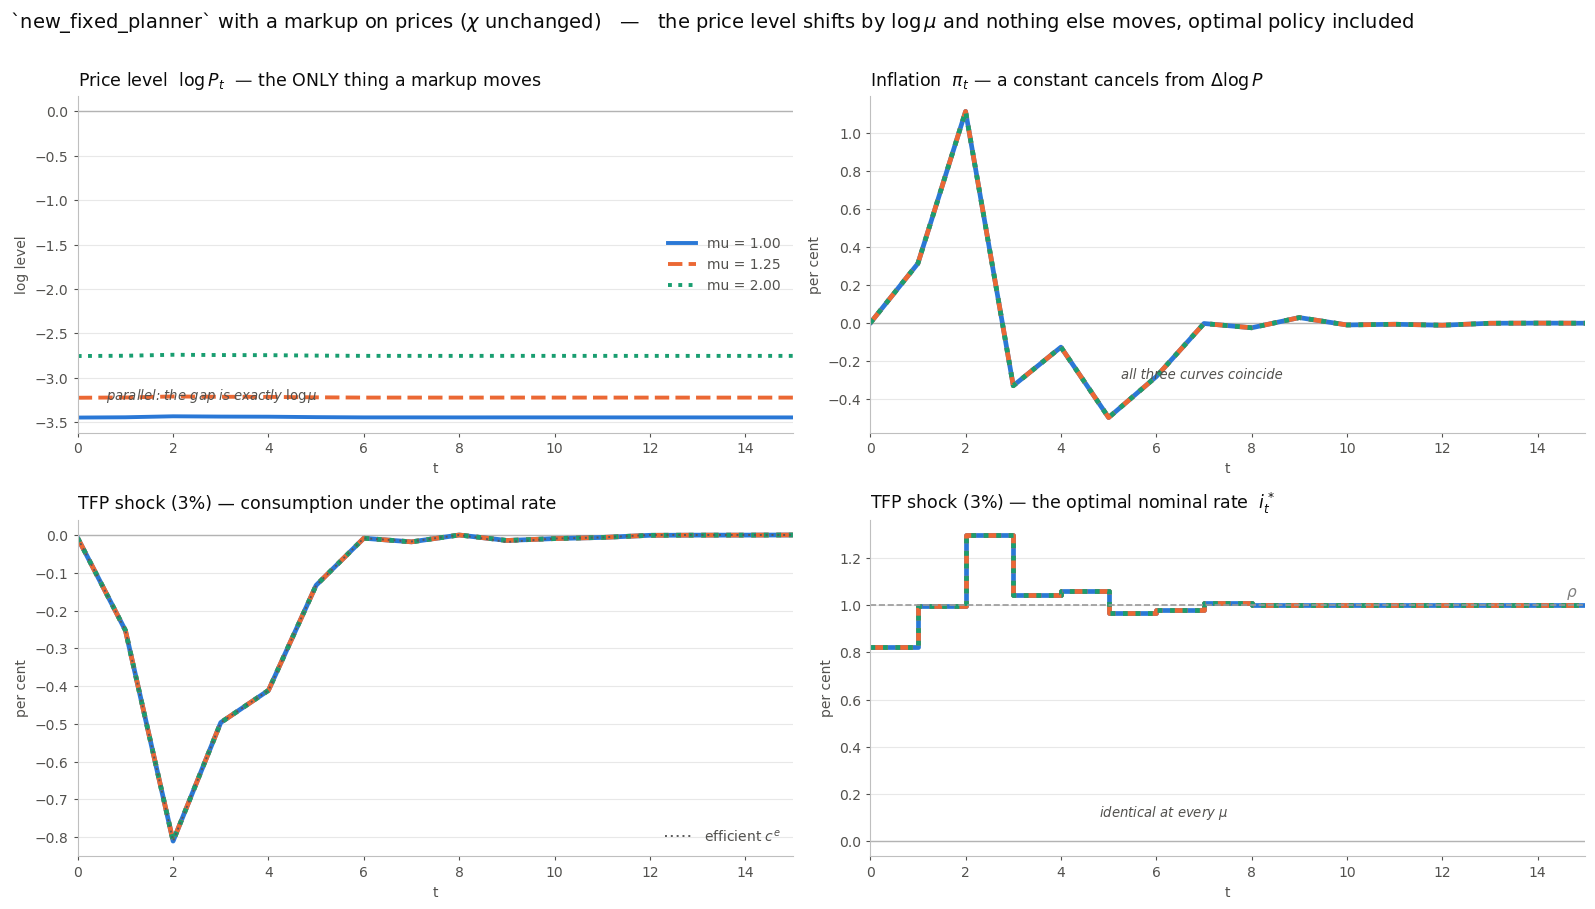

In [20]:
BLUE, ORANGE, GREEN, INK2, MUTED = '#2a78d6', '#eb6834', '#199e70', '#0b0b0b', '#52514e'
COL = dict(zip(MUS, [BLUE, ORANGE, GREEN]))
DSH = dict(zip(MUS, ['-', '--', ':']))
HZ, tt = 16, np.arange(16)

def sty(ax, title, ylab, xlab='t'):
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('0.75'); ax.spines['bottom'].set_color('0.75')
    ax.tick_params(colors=MUTED, labelsize=10, length=3)
    ax.grid(axis='y', color='0.91', lw=0.8); ax.set_axisbelow(True)
    ax.axhline(0, color='0.7', lw=1.0, zorder=1)
    ax.set_xlabel(xlab, color=MUTED, fontsize=10); ax.set_ylabel(ylab, color=MUTED, fontsize=10)
    ax.set_title(title, color=INK2, fontsize=12.5, loc='left', pad=8)

fig, axes = plt.subplots(2, 2, figsize=(16, 9)); fig.patch.set_facecolor('white')
CASE = 'TFP shock (3%)'

ax = axes[0, 0]; sty(ax, 'Price level  $\\log P_t$  — the ONLY thing a markup moves', 'log level')
ax.set_xlim(0, HZ - 1)
for mu in MUS:
    ax.plot(tt, np.log(OPT[(CASE, mu)][1]['P'])[:HZ], color=COL[mu], lw=2.8, ls=DSH[mu],
            label=f'mu = {mu:.2f}')
ax.legend(frameon=False, fontsize=10, labelcolor=MUTED, loc='center right')
ax.annotate('parallel: the gap is exactly $\\log\\mu$', xy=(0.04, 0.10),
            xycoords='axes fraction', fontsize=9.5, color=MUTED, style='italic')

ax = axes[0, 1]; sty(ax, 'Inflation  $\\pi_t$ — a constant cancels from $\\Delta\\log P$', 'per cent')
ax.set_xlim(0, HZ - 1)
for mu in MUS:
    ax.plot(tt, 100 * OPT[(CASE, mu)][1]['pi'][:HZ], color=COL[mu], lw=3.4, ls=DSH[mu])
ax.annotate('all three curves coincide', xy=(0.35, 0.16), xycoords='axes fraction',
            fontsize=9.5, color=MUTED, style='italic')

ax = axes[1, 0]; sty(ax, f'{CASE} — consumption under the optimal rate', 'per cent')
ax.set_xlim(0, HZ - 1)
for mu in MUS:
    ax.plot(tt, 100 * OPT[(CASE, mu)][1]['c'][:HZ], color=COL[mu], lw=3.4, ls=DSH[mu])
ax.plot(tt, 100 * OPT[(CASE, 1.0)][1]['c_eff'][:HZ], color='0.35', lw=1.4, ls=(0, (1, 2)),
        label='efficient $c^e$')
ax.legend(frameon=False, fontsize=10, labelcolor=MUTED, loc='lower right')

ax = axes[1, 1]; sty(ax, f'{CASE} — the optimal nominal rate  $i^*_t$', 'per cent')
ax.set_xlim(0, HZ - 1)
for mu in MUS:
    ip = np.r_[OPT[(CASE, mu)][0], np.full(HZ, rho)][:HZ]
    ax.step(tt, 100 * ip, where='post', color=COL[mu], lw=3.4, ls=DSH[mu])
ax.axhline(100 * rho, color='0.6', lw=1.2, ls='--')
ax.annotate(r'$\rho$', xy=(HZ - 1, 100 * rho), xytext=(-6, 6), textcoords='offset points',
            ha='right', color='0.5', fontsize=11)
ax.annotate('identical at every $\\mu$', xy=(0.32, 0.12), xycoords='axes fraction',
            fontsize=9.5, color=MUTED, style='italic')

fig.suptitle('`new_fixed_planner` with a markup on prices ($\\chi$ unchanged)   —   the price '
             'level shifts by $\\log\\mu$ and nothing else moves, optimal policy included',
             fontsize=14, color=INK2, x=0.006, ha='left', y=1.005)
fig.tight_layout()
fig.savefig('../semi_endo_new_fixed_planner_markup.png', dpi=200, bbox_inches='tight',
            facecolor='white')
plt.show()

## Summary

1. **A markup on prices is a pure level shift.**  $\log P$ moves by exactly $\log\mu$ —
   constant to $10^{-16}$, checked to $\mu=5$ — and `a_nat`, `d`, `pi` and labour are
   bit-identical.

2. **Optimal policy is unchanged too.**  $i^*$ and the welfare it attains agree to every digit
   at $\mu=1$, $1.25$ and $2$, for the no-shock case and for both shocks.  A markup gives the
   planner nothing to do.

3. **Why.**  $\mu$ multiplies every firm's price by the same constant, so it cancels from
   $p_i/P$ and hence from every quantity; and a constant cancels from $\pi_t=\Delta\log P$.
   This holds *because* the rate reprices every firm and every firm anticipates it — a
   proportional wedge cannot be leant on.

4. **Consistent with the other model.**  `fixed_wage_cohorts.ipynb` shows the same thing from
   the other direction: with a **flexible wage** the nominal rate is neutral to
   $4\times10^{-16}$ at every $\mu\in[0.5,\,2]$.  Market power is not what gives monetary
   policy a lever.

What *would* give the planner a level motive is a wedge between the labour condition the
equilibrium satisfies and the one the objective uses — which requires a labour-market
condition for the markup to enter.  This model has none: labour is residual,
$n_{\text{cons}}=c-a^{\text{phys}}$.  `fixed_wage_cohorts.ipynb` imposes
$W/P=\chi L^{\eta}C^{\gamma}$ and so does have somewhere for $\mu$ to act.